In [1]:
%config InlineBackend.figure_format = "retina"

import seaborn as sns

NEON = [
    "#00F5D4", "#8B5CF6", "#FF4D8D",
    "#FFD166", "#4CC9F0", "#B8F2E6"
]

sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette=NEON,
    font_scale=0.85,
    rc={
        # Keep the same plot dimensions
        "figure.figsize": (17, 7),
        "figure.dpi": 100,
        "savefig.dpi": 300,

        # Dark neon appearance
        "figure.facecolor": "#0B1020",
        "axes.facecolor": "#111827",
        "text.color": "#F8FAFC",
        "axes.labelcolor": "#CBD5E1",
        "axes.titlecolor": "#F8FAFC",
        "xtick.color": "#AAB4C5",
        "ytick.color": "#AAB4C5",

        # Smaller, sharper-looking typography
        "axes.titlesize": 12,
        "axes.titleweight": "semibold",
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,

        # Thin lines and subtle grid
        "lines.linewidth": 1.8,
        "lines.markersize": 4,
        "grid.color": "#334155",
        "grid.alpha": 0.25,
        "grid.linewidth": 0.5,

        # Clean borders and legends
        "axes.spines.top": False,
        "axes.spines.right": False,
        "legend.frameon": False,
    }
)

In [4]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df.job_posted_date)
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

c:\Users\abdel\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
df_exploded = df.explode('job_skills')

In [21]:
df_skills_count = df_exploded.groupby(['job_skills', 'job_title_short']).size().reset_index( name='skill_count').copy()

In [ ]:
df_skills_count = df_skills_count.sort_values(by='skill_count', ascending=False)

In [24]:
df_skills_count

,job_skills,job_title_short,skill_count
1480,python,Data Scientist,113711
1822,sql,Data Engineer,113130
1479,python,Data Engineer,108022
1821,sql,Data Analyst,92428
1823,sql,Data Scientist,78982
...,...,...,...
2173,webex,Senior Data Scientist,1
293,codecommit,Business Analyst,1
2233,xamarin,Machine Learning Engineer,1
1087,mlr,Machine Learning Engineer,1


In [33]:
job_title = 'Data Analyst'
top_skills = 14

df_skills_final = df_skills_count[df['job_title_short'] == job_title].head(top_skills)

C:\Users\abdel\AppData\Local\Temp\ipykernel_2680\1316854833.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_skills_final = df_skills_count[df['job_title_short'] == job_title].head(top_skills)


<Axes: ylabel='job_skills'>

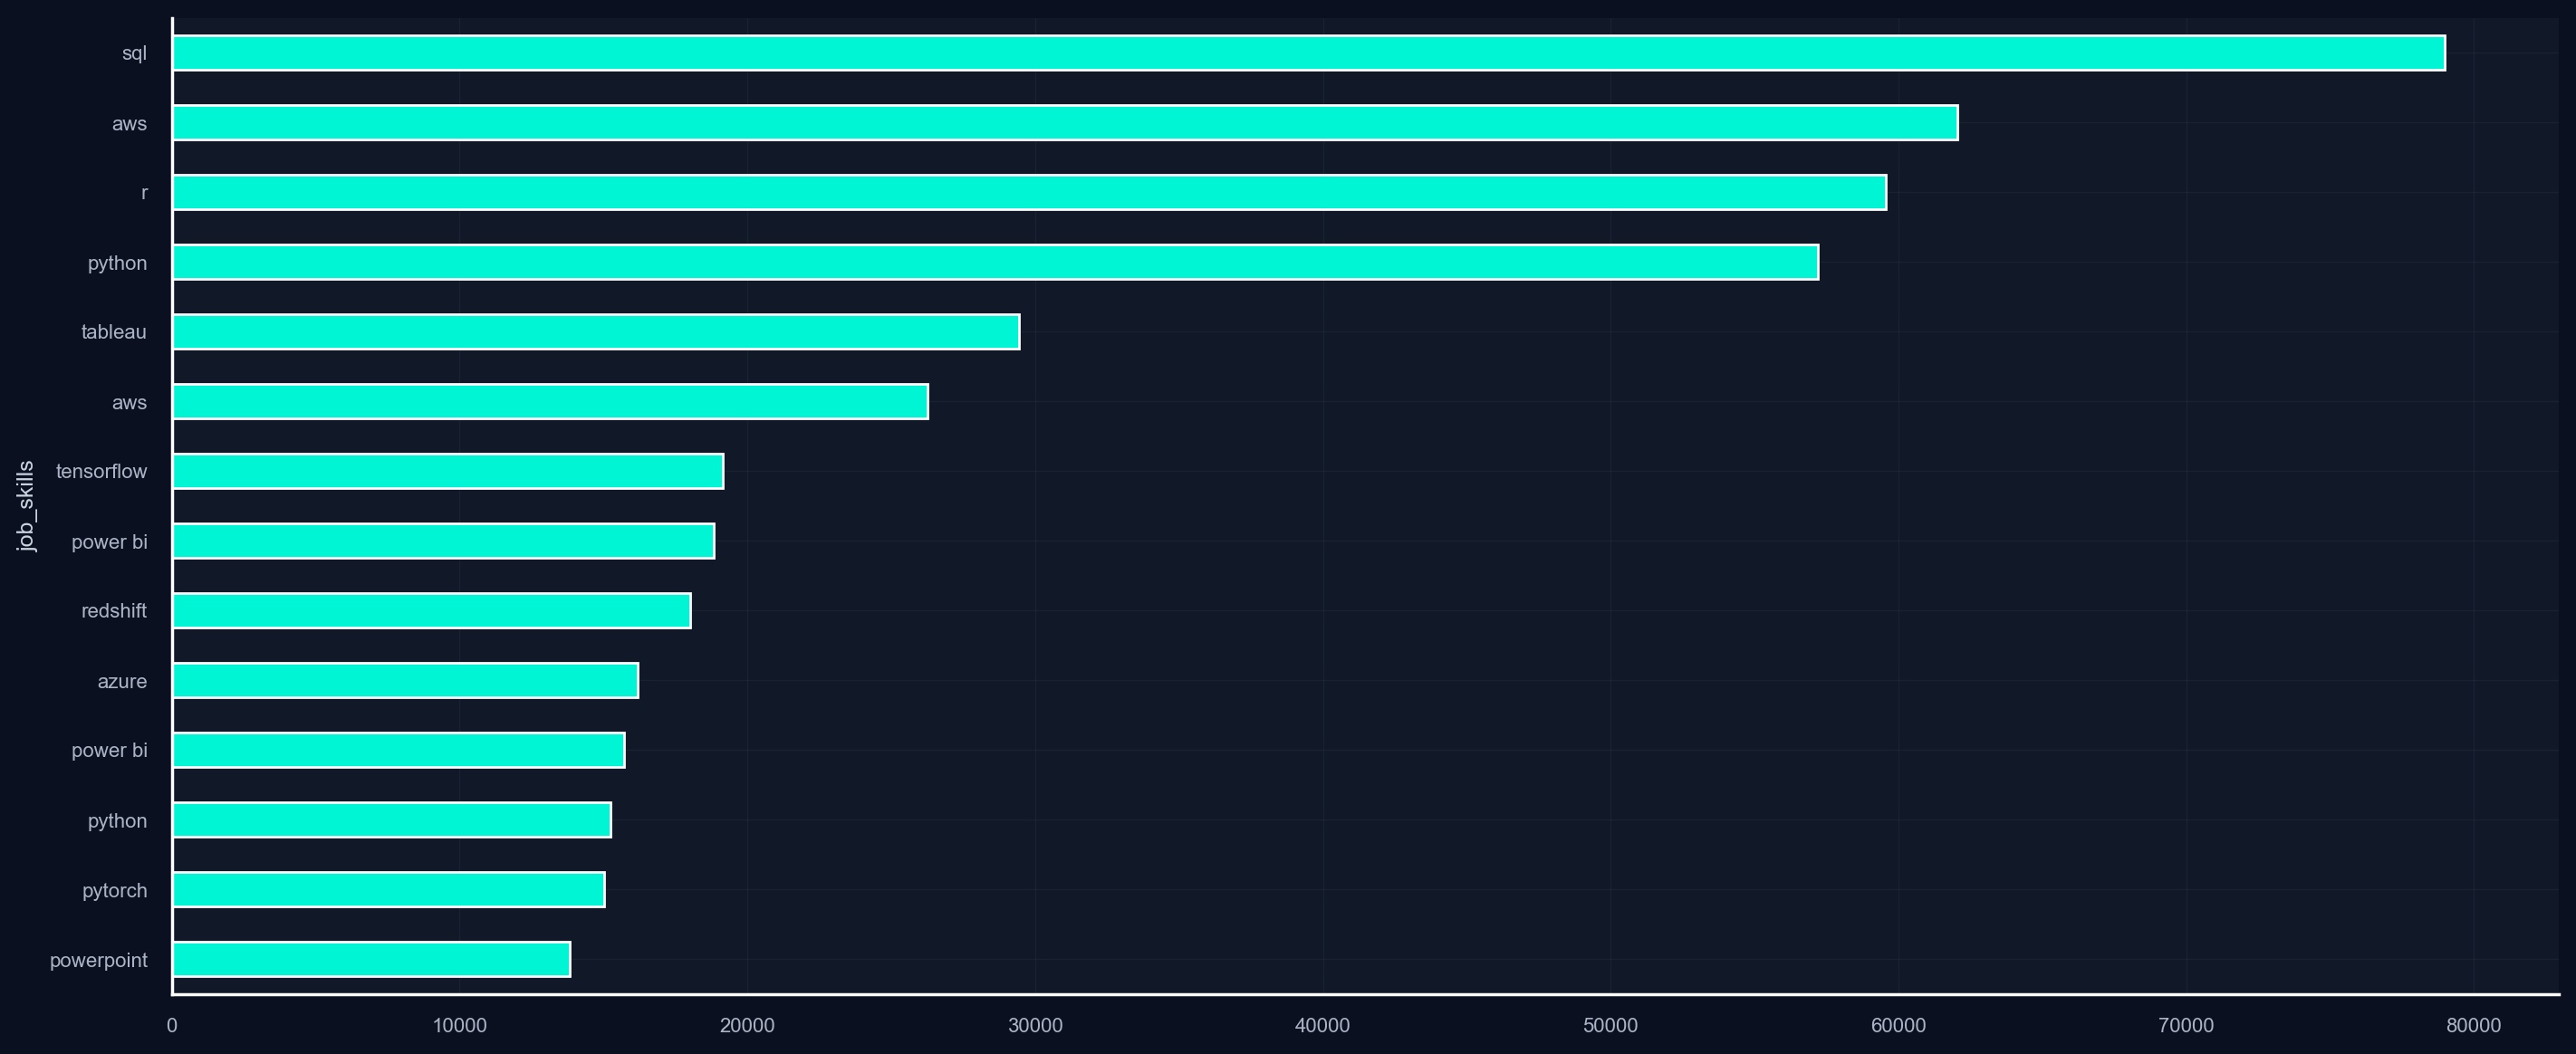

In [39]:
df_skills_final.sort_values( by='skill_count', ascending=True).plot(kind='barh', x='job_skills', y='skill_count', grid=True, legend=False )